# ISTA-based restoration of RGB images with a pre-designed NSOLT

Python counterpart of the MATLAB scripts in `examples/rgbdemos`:

| Section | MATLAB script | Degradation |
|---|---|---|
| [Deblurring](#Deblurring) | `quickstart_rgb_db.m` | Gaussian blur (σ = 2) + AWGN (σ = 5/255) |
| [Super-resolution](#Super-resolution) | `quickstart_rgb_sr.m` | Gaussian blur (σ = 2) + 2×2 decimation |
| [Inpainting](#Inpainting) | `quickstart_rgb_ip.m` | Random pixel loss (density 0.4) |

Each RGB component is restored by ISTA with the NSOLT designed for *lena128*
in `examples/icassp2014/results` (2×2 decimation, 4+4 channels, polyphase
order 4+4, one vanishing moment, 4 levels), as in MATLAB.

The building blocks are tested to agree with MATLAB for the same inputs:
`saivdr.degradation` with `saivdr.degradation.linearprocess`,
`IstaImRestoration2d` with `saivdr.restoration.ista.IstaImRestoration2d`, and
the network built by `load_nsoltx` with `saivdr.dictionary.generalfb.Analysis2dSystem`
and `Synthesis2dSystem`. The results differ from the MATLAB scripts because
the test image (MATLAB `peppers.png`) and the random numbers (noise and
pixel loss) differ.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import torch
from skimage import data

import saivdr.degradation as dg
from saivdr.dcnn import atomic_imshow
from saivdr.dcnn.matlab_compat import load_nsoltx
from saivdr.restoration import IstaImRestoration2d, psnr

DATA = pathlib.Path("../data")
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    # The tensors are small; many threads only add overhead
    torch.set_num_threads(min(8, torch.get_num_threads()))
torch.set_default_dtype(torch.float64)
print("device:", device)

device: cpu


## Source image

A 256×256 crop of `skimage.data.astronaut()` in place of `peppers.png`,
cropped at the same position (`px = py = 128`).

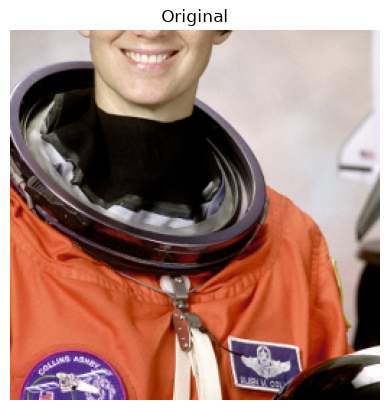

In [2]:
src = data.astronaut().astype(np.float64) / 255
org = torch.from_numpy(src[127:383, 127:383].copy()).permute(2, 0, 1).unsqueeze(0).to(device)  # 1 x 3 x H x W


def to_image(t):
    return t.squeeze(0).permute(1, 2, 0).clamp(0, 1).cpu().numpy()


plt.imshow(to_image(org))
plt.axis("off")
plt.title("Original");

## Pre-designed NSOLT

`nsoltx_icassp2014_lena128.mat` was exported in MATLAB by

```matlab
s = load('examples/icassp2014/results/nsolt_d2x2_c4+4_o4+4_v1_l4_n2048_lena128.mat');
saivdr_export_nsoltx(s.lppufbs{end}, 'nsoltx_icassp2014_lena128.mat')
```

`load_nsoltx` builds the network whose coefficients agree with
`Analysis2dSystem` (`FilterDomain = 'Frequency'`) of the filter bank.

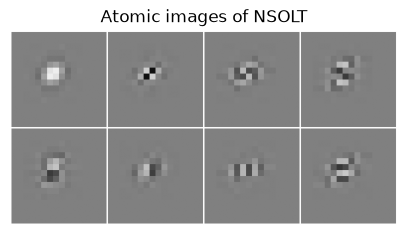

In [3]:
nLevels = 4
net = load_nsoltx(DATA / "nsoltx_icassp2014_lena128.mat", number_of_levels=nLevels, device=device)
analyzer, synthesizer = net.analyzer, net.synthesizer

# Atomic images of the filter bank (one level), as nsolt.atmimshow() in MATLAB
fig, ax = plt.subplots(figsize=(5, 3))
atomic_imshow(
    load_nsoltx(DATA / "nsoltx_icassp2014_lena128.mat", mode="Synthesizer", number_of_levels=1),
    patch_size=(16, 16),
    ax=ax,
)
ax.set_title("Atomic images of NSOLT");

## ISTA

`restore` runs `IstaImRestoration2d` (`Eps0 = 1e-6`, `MaxIter = 1000`, frame
bound 1) and records the PSNR at every iteration, as `StepMonitoringSystem`
does in MATLAB.

In [4]:
def restore(linproc, observed, lambda_):
    psnrs = []
    ista = IstaImRestoration2d(
        synthesizer=synthesizer,
        adj_of_synthesizer=analyzer,
        linear_process=linproc,
        lambda_=lambda_,
        step_monitor=lambda n, hu: psnrs.append(psnr(hu.clamp(0, 1), org)),
    )
    restored = ista(observed)
    print(f"{ista.n_iter} iterations, PSNR {psnrs[-1]:.2f} dB")
    return restored, psnrs


def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(to_image(img), interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")


results = {}

## Deblurring

`quickstart_rgb_db.m`: Gaussian blur (σ = 2, kernel 17×17, zero boundary)
followed by AWGN of σ = 5 (for [0, 255]), λ = 0.00185.

39 iterations, PSNR 24.96 dB


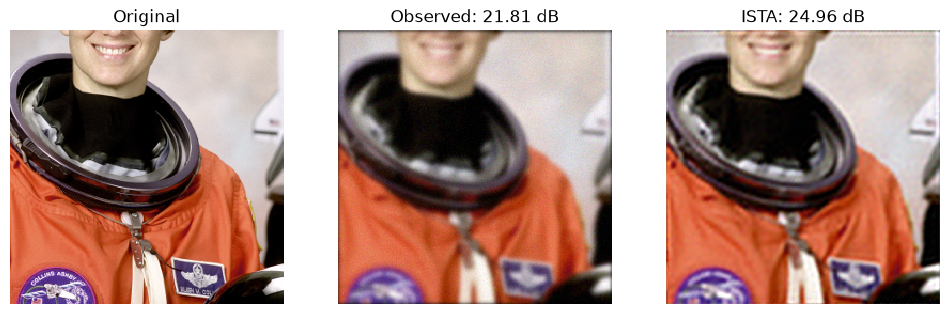

In [5]:
linproc = dg.BlurSystem(blur_type="Gaussian", sigma_of_gaussian_kernel=2)
awgn = dg.AdditiveWhiteGaussianNoiseSystem(
    mean=0, variance=(5 / 255) ** 2, generator=torch.Generator().manual_seed(0)
)
obs = dg.DegradationSystem(linproc, awgn)(org)
res, psnrs = restore(linproc, obs, lambda_=0.00185)
results["Deblurring"] = (psnr(obs, org), psnrs[-1])
show([org, obs, res], ["Original", f"Observed: {psnr(obs, org):.2f} dB", f"ISTA: {psnrs[-1]:.2f} dB"])

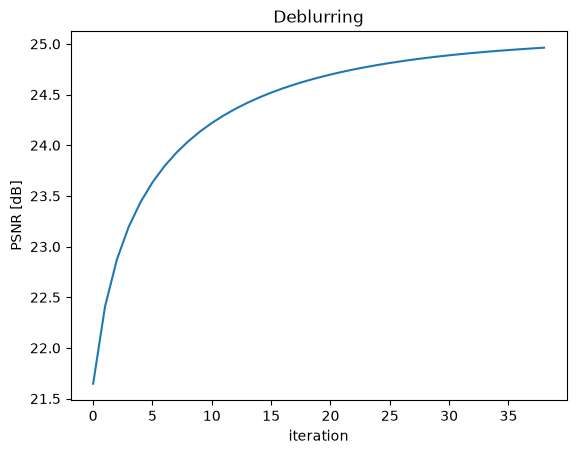

In [6]:
plt.plot(psnrs)
plt.xlabel("iteration")
plt.ylabel("PSNR [dB]")
plt.title("Deblurring");

## Super-resolution

`quickstart_rgb_sr.m`: Gaussian blur (σ = 2, kernel 9×9) and 2×2
decimation without noise, λ = 0.00018. A bicubic interpolation of the
observed image is shown for reference.

> In the MATLAB script, the linear process is first called with the
> original image by `DegradationSystem`, so that `IstaImRestoration2d` uses
> the maximum eigenvalue estimated for an image twice as large as the
> original. Here it is estimated for the actual size; the results differ
> slightly.

32 iterations, PSNR 25.32 dB


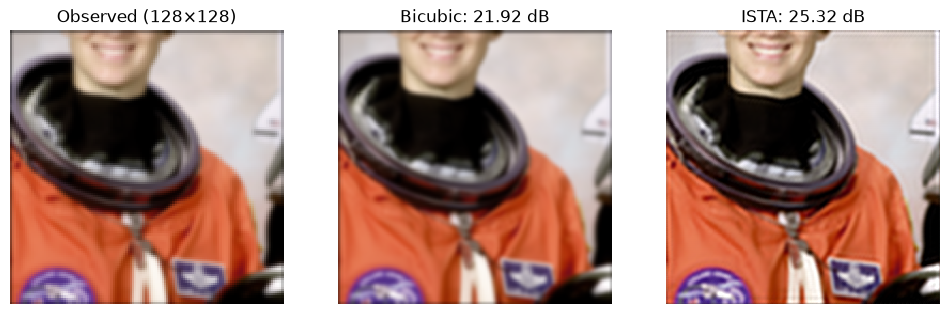

In [7]:
linproc = dg.DecimationSystem(
    vertical_decimation_factor=2,
    horizontal_decimation_factor=2,
    blur_type="Gaussian",
    sigma_of_gaussian_kernel=2,
    tol_of_power_method=1e-6,
)
obs = linproc.forward(org)
res, psnrs = restore(linproc, obs, lambda_=0.00018)
ref = torch.nn.functional.interpolate(obs, scale_factor=2, mode="bicubic", align_corners=False)
results["Super-resolution"] = (psnr(ref.clamp(0, 1), org), psnrs[-1])
show(
    [obs, ref, res],
    ["Observed (128×128)", f"Bicubic: {psnr(ref.clamp(0, 1), org):.2f} dB", f"ISTA: {psnrs[-1]:.2f} dB"],
)

## Inpainting

`quickstart_rgb_ip.m`: random pixel loss of density 0.4 without noise,
λ = 0.01. The mask is drawn by a PyTorch generator with seed 0 (MATLAB's
random numbers cannot be reproduced; pass `loss_type="Specified", mask=...`
to use a given mask).

135 iterations, PSNR 24.93 dB


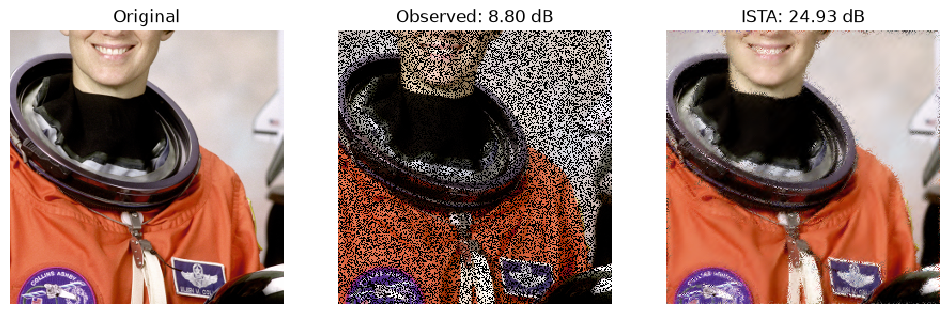

In [8]:
linproc = dg.PixelLossSystem(loss_type="Random", density=0.4, seed=0)
obs = linproc.forward(org)
res, psnrs = restore(linproc, obs, lambda_=0.01)
results["Inpainting"] = (psnr(obs, org), psnrs[-1])
show([org, obs, res], ["Original", f"Observed: {psnr(obs, org):.2f} dB", f"ISTA: {psnrs[-1]:.2f} dB"])

## Summary

In [9]:
print(f"{'':18s}{'reference':>12s}{'ISTA':>10s}")
for name, (before, after) in results.items():
    print(f"{name:18s}{before:10.2f} dB{after:7.2f} dB")
print("(reference: observed image, or bicubic interpolation for super-resolution)")

                     reference      ISTA
Deblurring             21.81 dB  24.96 dB
Super-resolution       21.92 dB  25.32 dB
Inpainting              8.80 dB  24.93 dB
(reference: observed image, or bicubic interpolation for super-resolution)
